# Chapitre 6 - Exercices 6.1 à 6.6

Régularité de l'estimateur de Nadaraya-Watson, moments du noyau équivalent, variance des
polynômes locaux, choix de la métrique pour des courbes, logistique localement constante
et modèles à coefficients variables.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch06_noyaux as nk
set_style()
GREEN, YELLOW, RED = COLORS[2], COLORS[3], COLORS[7]
rng = np.random.RandomState(0)

Données communes : le modèle de la figure 6.1, $Y = \sin(4X) + \varepsilon$,
$X\sim\mathcal U[0,1]$, $\varepsilon\sim\mathcal N(0, 1/3)$, avec ici $N = 40$ points (pour
que les phénomènes locaux soient bien visibles).

In [2]:
N = 40
x = np.sort(rng.uniform(0, 1, N))
y = np.sin(4 * x) + np.sqrt(1 / 3) * rng.normal(size=N)

## Exercice 6.1 : Dérivabilité de l'estimateur de Nadaraya-Watson

**Énoncé.** Montrer que l'estimateur de Nadaraya-Watson à largeur métrique fixe $\lambda$
et noyau gaussien est dérivable. Que peut-on dire avec le noyau d'Epanechnikov ? Et avec le
noyau d'Epanechnikov à largeur adaptative des plus proches voisins $\lambda(x_0)$ ?

**Rappel.** $\hat f(x_0) = \dfrac{N(x_0)}{S(x_0)}$ avec $N(x_0) = \sum_i K_i(x_0)\,y_i$,
$S(x_0) = \sum_i K_i(x_0)$ et $K_i(x_0) = D\big(|x_i - x_0|/h(x_0)\big)$.
Un quotient de fonctions dérivables est dérivable là où le dénominateur ne s'annule pas,
et sa dérivée est $(N'S - NS')/S^2$.

### (a) Noyau gaussien, largeur fixe

Ici $K_i(x_0) = \varphi\big((x_i - x_0)/\lambda\big)$ (comme $\varphi$ est paire, la valeur
absolue ne joue aucun rôle). C'est une composée de fonctions $C^\infty$, donc $K_i$ est
$C^\infty$, ainsi que $N$ et $S$. De plus $S(x_0) > 0$ pour tout $x_0$ car $\varphi > 0$.
Donc $\hat f$ est $C^\infty$ sur $\mathbb R$ entier.

**Calcul de la dérivée.** Comme $\varphi'(t) = -t\varphi(t)$, on obtient par dérivation
composée
$$
K_i'(x_0) = -\frac1\lambda\varphi'\!\left(\frac{x_i - x_0}{\lambda}\right)
= \frac{x_i - x_0}{\lambda^2}\,K_i(x_0).
$$
Notons $w_i = K_i/S$ les poids normalisés. Alors
$$
\hat f'(x_0) = \frac{N'}{S} - \frac{N}{S}\frac{S'}{S}
= \sum_i w_i\frac{x_i - x_0}{\lambda^2}y_i - \hat f(x_0)\sum_i w_i\frac{x_i - x_0}{\lambda^2}
= \frac1{\lambda^2}\sum_i w_i\,(x_i - x_0)\big(y_i - \hat f(x_0)\big) :
$$
c'est une **covariance pondérée** entre $x$ et $y$, divisée par $\lambda^2$.

In [3]:
lam = 0.1
def nw_gauss(t):
    return nk.nadaraya_watson(t, x, y, lam=lam, kernel="gaussian")

t0 = np.linspace(0, 1, 7)
W = nk.kernel_weights(t0, x, lam=lam, kernel="gaussian")
W = W / W.sum(1, keepdims=True)
formula = np.sum(W * (x[None, :] - t0[:, None]) * (y[None, :] - nw_gauss(t0)[:, None]), 1) / lam ** 2
eps = 1e-6
finite = (nw_gauss(t0 + eps) - nw_gauss(t0 - eps)) / (2 * eps)
print("écart max formule / différences finies : %.2e" % np.max(np.abs(formula - finite)))

écart max formule / différences finies : 1.71e-10


### (b) Noyau d'Epanechnikov, largeur fixe

$D(t) = \frac34(1-t^2)$ pour $|t|\le1$, $0$ sinon. On a :
- $D$ est **continue** (elle vaut 0 en $\pm1$ des deux côtés) ;
- $D(|t|) = \frac34(1-t^2)$ près de $t=0$ : la valeur absolue ne crée aucun problème en
  $x_0 = x_i$ ;
- en $t = 1$ : dérivée à gauche $D'(1^-) = -\frac32$, dérivée à droite $D'(1^+) = 0$.
  $D$ **n'est pas dérivable** en $\pm 1$.

Donc $K_i(x_0)$ est continue partout, et dérivable sauf aux deux points
$x_0 = x_i \pm \lambda$, où un point **entre ou sort** de la fenêtre.

**Conséquences pour $\hat f$.**
- $\hat f$ n'est définie que là où $S(x_0) > 0$, c'est-à-dire si au moins un $x_i$ est à
  distance $< \lambda$ de $x_0$ ; elle y est **continue**.
- Elle est dérivable partout sauf, éventuellement, en $x_0 = x_i\pm\lambda$. En un tel point
  $K_i(x_0) = 0$. Calculons le saut de $K_i'$ (dérivée à droite moins dérivée à gauche).
  En $x_0 = x_i + \lambda$ (le point **sort**) : à gauche $K_i = D\big((x_0 - x_i)/\lambda\big)$
  a pour dérivée $D'(1^-)/\lambda = -\frac{3}{2\lambda}$, à droite $K_i \equiv 0$ ; saut
  $+\frac{3}{2\lambda}$. En $x_0 = x_i - \lambda$ (le point **entre**) : à gauche 0, à
  droite $K_i = D\big((x_i - x_0)/\lambda\big)$ de dérivée $-D'(1^-)/\lambda = +\frac{3}{2\lambda}$ ;
  même saut. En reportant dans $\hat f' = (N'S - NS')/S^2 = \sum_j K_j'(y_j - \hat f)/S$
  (les autres $K_j'$ sont continues), le saut de $\hat f'$ vaut
  $$
  \frac{3}{2\lambda}\cdot\frac{y_i - \hat f(x_0)}{S(x_0)},
  $$
  **non nul** sauf si $y_i = \hat f(x_0)$ (cas exceptionnel). Génériquement, $\hat f$ a donc
  un **point anguleux** en chaque $x_i\pm\lambda$.

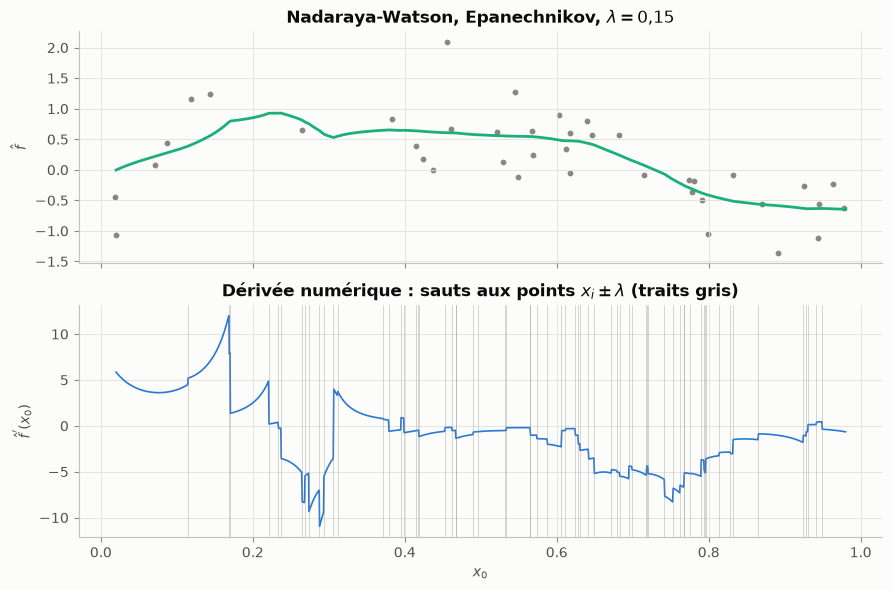

In [4]:
lam = 0.15
tt = np.linspace(0.02, 0.98, 4001)
fe = nk.nadaraya_watson(tt, x, y, lam=lam, kernel="epanechnikov")
dfe = np.gradient(fe, tt)
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(tt, fe, color=GREEN); axes[0].scatter(x, y, s=10, color=GRAY)
axes[0].set_title("Nadaraya-Watson, Epanechnikov, $\\lambda = 0{,}15$"); axes[0].set_ylabel("$\\hat f$")
axes[1].plot(tt, dfe, color=BLUE, lw=1.2)
for xi in x:
    for s in (-lam, lam):
        if 0.02 < xi + s < 0.98:
            axes[1].axvline(xi + s, color=GRAY, lw=0.4, alpha=0.6)
axes[1].set_title("Dérivée numérique : sauts aux points $x_i \\pm \\lambda$ (traits gris)")
axes[1].set_xlabel("$x_0$"); axes[1].set_ylabel("$\\hat f'(x_0)$")
plt.tight_layout(); plt.show()

Vérifions la formule du saut en un point $x_0 = x_i + \lambda$ :

In [5]:
i = 15
xc = x[i] + lam
h = 1e-7
left = (nk.nadaraya_watson([xc - h], x, y, lam=lam)[0] - nk.nadaraya_watson([xc - 2 * h], x, y, lam=lam)[0]) / h
right = (nk.nadaraya_watson([xc + 2 * h], x, y, lam=lam)[0] - nk.nadaraya_watson([xc + h], x, y, lam=lam)[0]) / h
S = nk.kernel_weights([xc], x, lam=lam)[0].sum()
fx = nk.nadaraya_watson([xc], x, y, lam=lam)[0]
print("saut observé  : %.4f" % (right - left))
print("saut théorique : %.4f" % (3 / (2 * lam) * (y[i] - fx) / S))

saut observé  : 1.3972
saut théorique : 1.3972


### (c) Epanechnikov à largeur adaptative (k plus proches voisins)

Maintenant $h(x_0) = |x_0 - x_{[k]}|$, distance au $k$-ième voisin.

- **Continuité de $h$** : $h(x_0)$ est la $k$-ième plus petite des fonctions continues
  $|x_0 - x_i|$, donc continue ; elle est affine par morceaux, de pente $\pm1$.
- **Le $k$-ième voisin a un poids nul** : $|x_{[k]} - x_0|/h(x_0) = 1$ et $D(1) = 0$. En
  pratique la moyenne porte donc sur $k - 1$ points.
- Quand le $k$-ième voisin **change** (un point $a$ à gauche et un point $b$ à droite sont
  à égale distance), les deux points concernés ont un poids nul de part et d'autre : pas de
  saut, $\hat f$ reste **continue** (et elle est toujours définie : $S > 0$ dès que $k\ge 2$
  sans ex æquo).
- Mais en ce point la pente de $h$ passe de $+1$ à $-1$ (ou l'inverse) : $h$ a un **point
  anguleux**. Tous les poids $K_j = D(|x_j - x_0|/h(x_0))$ des points intérieurs ont alors
  une dérivée qui saute, et $\hat f'$ saute génériquement.

Conclusion : avec la largeur adaptative, $\hat f$ est continue mais présente des points
anguleux aux points de changement du $k$-ième voisin (milieux $(a + b)/2$ de paires de
points d'apprentissage). Même un noyau régulier (tri-cube, gaussien tronqué) ne suffirait
pas à rendre $\hat f$ dérivable, puisque c'est $h(x_0)$ lui-même qui ne l'est pas.

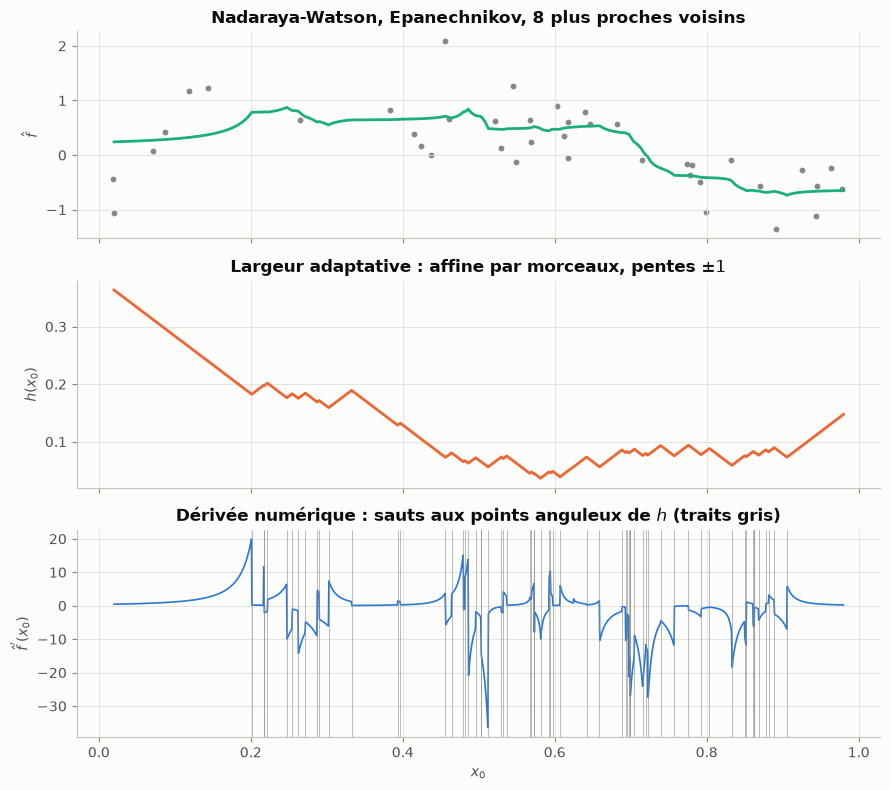

In [6]:
k = 8
fk = nk.nadaraya_watson(tt, x, y, k=k, kernel="epanechnikov")
hk = np.sort(nk.distances(tt, x), axis=1)[:, k - 1]
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
axes[0].plot(tt, fk, color=GREEN); axes[0].scatter(x, y, s=10, color=GRAY)
axes[0].set_title("Nadaraya-Watson, Epanechnikov, 8 plus proches voisins"); axes[0].set_ylabel("$\\hat f$")
axes[1].plot(tt, hk, color=ORANGE); axes[1].set_ylabel("$h(x_0)$")
axes[1].set_title("Largeur adaptative : affine par morceaux, pentes $\\pm 1$")
dfk = np.gradient(fk, tt)
kinks = tt[1:-1][np.abs(np.diff(np.sign(np.diff(hk)))) > 0]
axes[2].plot(tt, dfk, color=BLUE, lw=1.2)
for kk in kinks:
    axes[2].axvline(kk, color=GRAY, lw=0.4)
axes[2].set_title("Dérivée numérique : sauts aux points anguleux de $h$ (traits gris)")
axes[2].set_xlabel("$x_0$"); axes[2].set_ylabel("$\\hat f'(x_0)$")
plt.tight_layout(); plt.show()

> **À retenir.** Gaussien à largeur fixe : $\hat f\in C^\infty$. Epanechnikov à largeur
> fixe : $\hat f$ continue (là où elle est définie) mais anguleuse en chaque $x_i\pm\lambda$.
> Epanechnikov à largeur des k-ppv : $\hat f$ continue mais anguleuse là où le $k$-ième
> voisin change, car la largeur $h(x_0)$ elle-même n'est pas dérivable.

## Exercice 6.2 : Moments du noyau équivalent

**Énoncé.** Pour la régression linéaire locale, montrer que $\sum_{i=1}^N (x_i - x_0)\,l_i(x_0) = 0$.
On pose $b_j(x_0) = \sum_{i=1}^N (x_i - x_0)^j\,l_i(x_0)$. Montrer que $b_0(x_0) = 1$ pour la
régression polynomiale locale de tout degré (constantes locales comprises), et que
$b_j(x_0) = 0$ pour tout $j \in\{1,\dots,k\}$ pour la régression polynomiale locale de degré
$k$. Quelles conséquences pour le biais ?

**Rappels.** La régression polynomiale locale de degré $k$ en $x_0$ minimise
$\sum_i K_\lambda(x_0,x_i)\big(y_i - \sum_{j=0}^k\theta_j(x_i - x_0)^j\big)^2$ (on écrit le
polynôme dans la base centrée en $x_0$, ce qui ne change pas l'ensemble des polynômes de
degré $\le k$, donc pas l'ajustement) et pose $\hat f(x_0) = \hat\theta_0$ (valeur du
polynôme en $x_0$). Avec $\mathbf B$ la matrice $N\times(k+1)$ de terme $(x_i - x_0)^j$ :
$$
\hat f(x_0) = e_1^T(\mathbf B^T\mathbf W\mathbf B)^{-1}\mathbf B^T\mathbf W\mathbf y = \sum_i l_i(x_0)y_i,
$$
avec $e_1 = (1,0,\dots,0)^T$, en supposant $\mathbf B^T\mathbf W\mathbf B$ inversible.

**Lemme (reproduction des polynômes).** Si $\mathbf y = \mathbf B\theta$ pour un vecteur
$\theta$ (les $y_i$ sont **exactement** les valeurs d'un polynôme $P$ de degré $\le k$), alors
$$
(\mathbf B^T\mathbf W\mathbf B)^{-1}\mathbf B^T\mathbf W\mathbf B\theta = \theta,
$$
donc $\hat f(x_0) = e_1^T\theta = \theta_0 = P(x_0)$. Autrement dit
$\sum_i l_i(x_0)P(x_i) = P(x_0)$ : la méthode est **exacte** sur les polynômes de degré
$\le k$. (Intuition : le critère vaut 0 en $\theta$, son minimum, et il est unique.)

**Preuve des trois affirmations.** On applique le lemme à $P(x) = (x - x_0)^j$, de degré
$j\le k$ : $b_j(x_0) = \sum_i l_i(x_0)(x_i - x_0)^j = P(x_0) = 0^j$, qui vaut $1$ si $j=0$
et $0$ si $1\le j\le k$.
- $j = 0$ : $b_0(x_0) = \sum_i l_i(x_0) = 1$ pour tout degré $k\ge 0$ (pour $k = 0$, c'est
  juste que les poids de Nadaraya-Watson somment à 1).
- $k = 1$, $j = 1$ : $\sum_i(x_i - x_0)\,l_i(x_0) = 0$ pour la régression linéaire locale.
- Plus généralement $b_j(x_0) = 0$ pour $1\le j\le k$.

**Conséquence pour le biais.** Si $f$ est assez régulière, la formule de Taylor donne
$f(x_i) = \sum_{j\ge0}\frac{f^{(j)}(x_0)}{j!}(x_i - x_0)^j$ et, $\mathbb E y_i = f(x_i)$,
$$
\mathbb E\hat f(x_0) - f(x_0) = \sum_i l_i(x_0)f(x_i) - f(x_0)
= \sum_{j\ge k+1}\frac{f^{(j)}(x_0)}{j!}\,b_j(x_0).
$$
Le biais ne dépend que des dérivées d'ordre $\ge k+1$ : il est **nul** si $f$ est un
polynôme de degré $\le k$. Comme les poids sont concentrés sur $|x_i - x_0|\le\lambda$,
$|b_j(x_0)|\le\lambda^j\sum_i|l_i(x_0)|$, d'où un biais en $O(\lambda^{k+1})$.

Vérification numérique des moments $b_j(x_0)$, pour $x_0$ au bord et à l'intérieur :

In [7]:
for x0 in [0.01, 0.5]:
    print("x0 = %.2f" % x0)
    for deg in range(4):
        l = nk.local_weights_matrix([x0], x, lam=0.35, degree=deg, kernel="tricube")[0]
        bj = [np.sum((x - x0) ** j * l) for j in range(5)]
        print("  degré %d : " % deg + "  ".join("b%d=%+.1e" % (j, v) for j, v in enumerate(bj)))

x0 = 0.01
  degré 0 : b0=+1.0e+00  b1=+7.1e-02  b2=+8.5e-03  b3=+1.3e-03  b4=+2.4e-04
  degré 1 : b0=+1.0e+00  b1=+2.1e-17  b2=-6.0e-03  b3=-1.8e-03  b4=-4.7e-04
  degré 2 : b0=+1.0e+00  b1=+4.2e-17  b2=-1.8e-18  b3=+3.7e-04  b4=+1.5e-04
  degré 3 : b0=+1.0e+00  b1=-1.4e-16  b2=-3.6e-17  b3=+2.0e-17  b4=-2.3e-05
x0 = 0.50
  degré 0 : b0=+1.0e+00  b1=+4.2e-02  b2=+1.2e-02  b3=+1.2e-03  b4=+4.0e-04
  degré 1 : b0=+1.0e+00  b1=+7.4e-18  b2=+9.0e-03  b3=-1.8e-04  b4=+2.2e-04
  degré 2 : b0=+1.0e+00  b1=+8.7e-19  b2=-6.5e-19  b3=-1.1e-03  b4=-4.0e-04
  degré 3 : b0=+1.0e+00  b1=+3.5e-18  b2=-2.6e-18  b3=+1.6e-19  b4=-2.8e-04


Les $b_j$ s'annulent (à la précision machine) exactement pour $1\le j\le k$ ; $b_{k+1}$ ne
s'annule pas. Illustrons l'ordre du biais $O(\lambda^{k+1})$ au **bord** : on calcule le
biais exact $\sum_i l_i(x_0)f(x_i) - f(x_0)$ (aucune simulation nécessaire, c'est linéaire)
sur un plan régulier dense, pour $f(x) = e^{x}$.

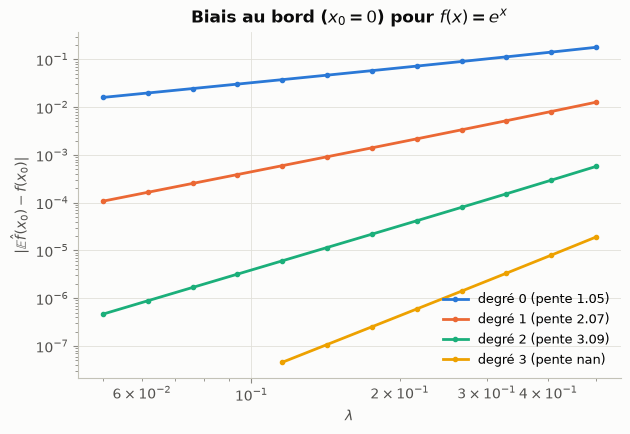

In [8]:
xd = np.linspace(0, 1, 2001)
fd = np.exp(xd)
lams = np.geomspace(0.05, 0.5, 12)
plt.figure(figsize=(7, 4.5))
for deg in range(4):
    bias = [abs(nk.local_weights_matrix([0.0], xd, lam=l, degree=deg, kernel="tricube")[0] @ fd - 1.0)
            for l in lams]
    slope = np.polyfit(np.log(lams), np.log(bias), 1)[0]
    plt.loglog(lams, bias, "o-", ms=3, label="degré %d (pente %.2f)" % (deg, slope))
plt.title("Biais au bord ($x_0 = 0$) pour $f(x) = e^x$")
plt.xlabel("$\\lambda$"); plt.ylabel("$|\\mathbb{E}\\hat f(x_0) - f(x_0)|$"); plt.legend(); plt.show()

Les pentes en échelle log-log valent environ $k+1$ : biais en $O(\lambda^{k+1})$.

> **À retenir.** La régression polynomiale locale de degré $k$ reproduit exactement les
> polynômes de degré $\le k$ ; ses moments $b_1,\dots,b_k$ sont nuls et le biais ne
> fait intervenir que $f^{(k+1)}, f^{(k+2)},\dots$, d'où un biais en $O(\lambda^{k+1})$,
> y compris au bord.

## Exercice 6.3 : La norme du noyau équivalent croît avec le degré

**Énoncé.** Montrer que $\|l(x)\|$ (section 6.1.2) augmente avec le degré du polynôme local.

**Rappel.** $\operatorname{Var}\hat f(x_0) = \sigma^2\|l(x_0)\|^2$ : l'énoncé dit que la
variance augmente avec le degré (figure 6.6). Nous allons voir que c'est **exactement** vrai
pour une norme pondérée adaptée (et donc pour la norme euclidienne avec un noyau
rectangulaire), mais seulement « en général » pour la norme euclidienne avec un noyau
quelconque.

### Caractérisation variationnelle du noyau équivalent

Restreignons-nous aux $n$ points de la fenêtre, de poids $w_i = K_\lambda(x_0, x_i) > 0$
(les autres ont $l_i = 0$ puisque $l^T = e_1^T(\mathbf B^T\mathbf W\mathbf B)^{-1}\mathbf B^T\mathbf W$
contient le facteur $\mathbf W$). L'exercice 6.2 montre que $l = l(x_0)$ vérifie les
$k+1$ contraintes linéaires $\mathbf B^Tl = e_1$, c'est-à-dire $b_j = \delta_{j0}$.

**Proposition.** $l$ est l'unique solution de
$$
\min_{u\in\mathbb R^n}\ \sum_i \frac{u_i^2}{w_i} = u^T\mathbf W^{-1}u
\quad\text{sous la contrainte}\quad \mathbf B^Tu = e_1 .
$$

**Preuve (multiplicateurs de Lagrange).** Le critère est strictement convexe (car
$\mathbf W^{-1}$ est définie positive) et les contraintes sont affines : un point
stationnaire du lagrangien $\mathcal L(u,\mu) = u^T\mathbf W^{-1}u - 2\mu^T(\mathbf B^Tu - e_1)$
est l'unique minimum.
- $\partial\mathcal L/\partial u = 2\mathbf W^{-1}u - 2\mathbf B\mu = 0$ donne $u = \mathbf W\mathbf B\mu$.
- La contrainte donne $\mathbf B^T\mathbf W\mathbf B\mu = e_1$, soit $\mu = (\mathbf B^T\mathbf W\mathbf B)^{-1}e_1$.
- Donc $u = \mathbf W\mathbf B(\mathbf B^T\mathbf W\mathbf B)^{-1}e_1$, qui est exactement
  $l(x_0)$ (transposer la formule (6.8)). $\square$

**Conséquence.** Passer du degré $k$ au degré $k+1$ **ajoute** une contrainte
($b_{k+1} = 0$) : l'ensemble admissible rétrécit, donc le minimum ne peut qu'augmenter :
$$
\|l^{(k)}(x_0)\|_{\mathbf W^{-1}}^2 \le \|l^{(k+1)}(x_0)\|_{\mathbf W^{-1}}^2,
\qquad \|u\|^2_{\mathbf W^{-1}} = \sum_i u_i^2/w_i .
$$
Pour le **noyau rectangulaire** ($w_i = c$ constant sur la fenêtre, par exemple les k-ppv
non pondérés), $\|u\|^2_{\mathbf W^{-1}} = \|u\|^2/c$ : la norme euclidienne $\|l(x)\|$
croît donc avec le degré, ce qui démontre l'énoncé dans ce cas.

Vérification numérique de l'inégalité pondérée (noyau tri-cube) et de l'inégalité
euclidienne (noyau rectangulaire), sur une grille de points :

In [9]:
G = np.linspace(0, 1, 201)
def norms(kernel, weighted):
    out = []
    for deg in range(4):
        L = nk.local_weights_matrix(G, x, lam=0.3, degree=deg, kernel=kernel)
        if weighted:
            Wk = nk.kernel_weights(G, x, lam=0.3, kernel=kernel)
            out.append(np.array([np.sum(L[a, Wk[a] > 0] ** 2 / Wk[a, Wk[a] > 0]) for a in range(len(G))]))
        else:
            out.append(np.sum(L ** 2, axis=1))
    return np.array(out)

box = lambda t: (np.abs(np.asarray(t)) <= 1).astype(float)
Nw = norms("tricube", True)
Nb = norms(box, False)
print("tri-cube, norme pondérée : monotone partout ?", bool(np.all(np.diff(Nw, axis=0) >= -1e-12)))
print("rectangulaire, norme euclidienne : monotone partout ?", bool(np.all(np.diff(Nb, axis=0) >= -1e-12)))

tri-cube, norme pondérée : monotone partout ? True
rectangulaire, norme euclidienne : monotone partout ? True


### Et la norme euclidienne avec un noyau non constant ?

L'argument ne s'applique plus tel quel, et l'inégalité **peut** être (légèrement) fausse.
Typiquement à l'intérieur, avec un plan presque symétrique autour de $x_0$, les noyaux
équivalents de degré $2m$ et $2m+1$ sont presque identiques (exactement identiques pour un
plan symétrique : la contrainte $b_{2m+1} = 0$ est alors automatiquement satisfaite), et
de petites asymétries peuvent inverser l'ordre. Cherchons un tel cas :

In [10]:
Ne = norms("tricube", False)
viol = np.where(np.any(np.diff(Ne, axis=0) < -1e-12, axis=0))[0]
rel = np.diff(Ne, axis=0) / Ne[:-1]
print("proportion de points de la grille où ||l|| n'est pas croissante : %.2f" % (len(viol) / len(G)))
print("plus forte baisse relative de ||l||^2 d'un degré au suivant : %.2f %%" % (-100 * rel.min()))
for d in range(3):
    print("  degré %d -> %d : %d points de la grille" % (d, d + 1, np.sum(rel[d] < -1e-12)))
a = viol[0]
print("exemple x0 = %.3f : ||l||^2 par degré = %s" % (G[a], np.round(Ne[:, a], 5)))

proportion de points de la grille où ||l|| n'est pas croissante : 0.18
plus forte baisse relative de ||l||^2 d'un degré au suivant : 3.48 %
  degré 0 -> 1 : 23 points de la grille
  degré 1 -> 2 : 3 points de la grille
  degré 2 -> 3 : 11 points de la grille
exemple x0 = 0.025 : ||l||^2 par degré = [0.16107 0.32245 0.38629 0.38614]


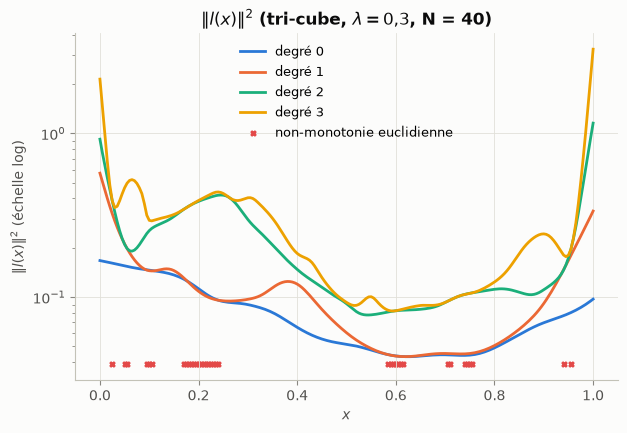

In [11]:
plt.figure(figsize=(7, 4.5))
for deg in range(4):
    plt.plot(G, Ne[deg], label="degré %d" % deg)
plt.scatter(G[viol], np.full(len(viol), Ne.min() * 0.9), marker="x", color=RED, s=12,
            label="non-monotonie euclidienne")
plt.yscale("log")
plt.title("$\\|l(x)\\|^2$ (tri-cube, $\\lambda = 0{,}3$, N = 40)")
plt.xlabel("$x$"); plt.ylabel("$\\|l(x)\\|^2$ (échelle log)"); plt.legend(); plt.show()

Les inversions existent donc bien pour la norme euclidienne, mais elles restent faibles en
valeur relative ; elles se produisent là où deux degrés consécutifs donnent des noyaux
équivalents presque identiques. La tendance générale (et la conclusion pratique : plus de
degré, plus de variance) est celle de la figure 6.6.

> **À retenir.** Le noyau équivalent est la solution de norme minimale (pour
> $\sum_i u_i^2/w_i$) parmi les poids qui reproduisent les polynômes de degré $\le k$ ;
> augmenter le degré ajoute des contraintes, donc augmente cette norme. Pour un noyau
> rectangulaire c'est exactement la variance $\sigma^2\|l\|^2$ ; pour un noyau quelconque
> c'est la tendance générale (fig. 6.6), à de petites exceptions près.

## Exercice 6.4 : Métrique pour des prédicteurs issus de courbes

**Énoncé.** Les $p$ prédicteurs $X$ proviennent de l'échantillonnage de courbes analogiques
assez régulières en $p$ abscisses régulièrement espacées. Soit
$\operatorname{Cov}(X\mid Y) = \Sigma$ la covariance conditionnelle des prédicteurs,
supposée peu dépendante de $Y$. Discuter la nature du choix de Mahalanobis
$\mathbf A = \Sigma^{-1}$ pour la métrique de (6.14). Comparer à $\mathbf A = \mathbf I$.
Comment construire un noyau $\mathbf A$ qui (a) atténue les composantes de haute fréquence
dans la distance ; (b) les ignore complètement ?

**Rappel.** La métrique (6.14) utilise la forme quadratique $(x - x_0)^T\mathbf A(x - x_0)$.
Écrivons la décomposition spectrale $\Sigma = \sum_{j=1}^p d_j u_ju_j^T$,
$d_1\ge\dots\ge d_p > 0$, $(u_j)$ orthonormée. Pour des courbes **régulières**, les premiers
vecteurs propres $u_j$ sont des fonctions lisses (basses fréquences) et les derniers
oscillent beaucoup (hautes fréquences) ; les $d_j$ décroissent très vite, car une courbe
régulière a peu d'énergie en haute fréquence.

Avec $z = x - x_0$ et ses coordonnées $c_j = u_j^Tz$ dans la base propre :
- $\mathbf A = \mathbf I$ : $z^Tz = \sum_j c_j^2$, toutes les directions comptent pareil ;
  la distance est dominée par les composantes de grande variance (basses fréquences).
- $\mathbf A = \Sigma^{-1}$ : $z^T\Sigma^{-1}z = \sum_j c_j^2/d_j$. Les composantes de
  **haute fréquence**, de très petite variance $d_j$, reçoivent un poids **énorme**. Or
  elles sont essentiellement du bruit (et $\Sigma$ y est mal estimée, presque singulière) :
  la distance de Mahalanobis devient instable et dominée par le bruit. C'est en général un
  **mauvais** choix ici.

**(a) Atténuer les hautes fréquences.** On prend $\mathbf A = \sum_j\gamma_j v_jv_j^T$ avec
une base $(v_j)$ ordonnée par fréquence croissante (vecteurs propres de $\Sigma$, base de
Fourier/cosinus, B-splines orthonormalisées…) et des poids $\gamma_j$ **décroissants**
(par exemple $\gamma_j = 1/(1+(j/j_0)^4)$, ou $\gamma_j = d_j$, soit $\mathbf A = \Sigma$).
De façon équivalente, $\mathbf A = \mathbf S^T\mathbf S$ avec $\mathbf S$ un **filtre
passe-bas** (lisseur) : on compare les courbes **lissées**.

**(b) Les ignorer complètement.** On prend $\gamma_j = 1$ pour $j\le M$ et $0$ au-delà :
$\mathbf A = \mathbf H_M\mathbf H_M^T$ est le projecteur sur les $M$ premières fonctions
lisses. La distance ne dépend que des coordonnées de la courbe dans cette base (c'est la
même idée que la régression sur une base de splines naturelles de l'exemple des phonèmes,
section 5.2.3 du livre). $\mathbf A$ est alors semi-définie positive de rang $M$.

### Illustration sur les phonèmes « aa » / « ao »

Chaque observation est un log-périodogramme échantillonné en 256 fréquences. On estime
$\Sigma$ par la covariance intra-classe et on regarde ses vecteurs propres.

In [12]:
ph = datasets.load_phoneme()
ph = ph[ph["g"].isin(["aa", "ao"])]
Xp = ph.filter(like="x.").to_numpy(float)
yp = (ph["g"] == "ao").to_numpy(int)
trp = ph["speaker"].str.startswith("train").to_numpy()
Xtr, ytr, Xte, yte = Xp[trp], yp[trp], Xp[~trp], yp[~trp]
mus = np.array([Xtr[ytr == c].mean(0) for c in (0, 1)])
Rc = Xtr - mus[ytr]
Sigma = Rc.T @ Rc / (len(ytr) - 2)
dS, US = np.linalg.eigh(Sigma)
dS, US = dS[::-1], US[:, ::-1]
print("apprentissage : %d courbes, test : %d courbes, p = %d" % (len(ytr), len(yte), Xp.shape[1]))

apprentissage : 1278 courbes, test : 439 courbes, p = 256


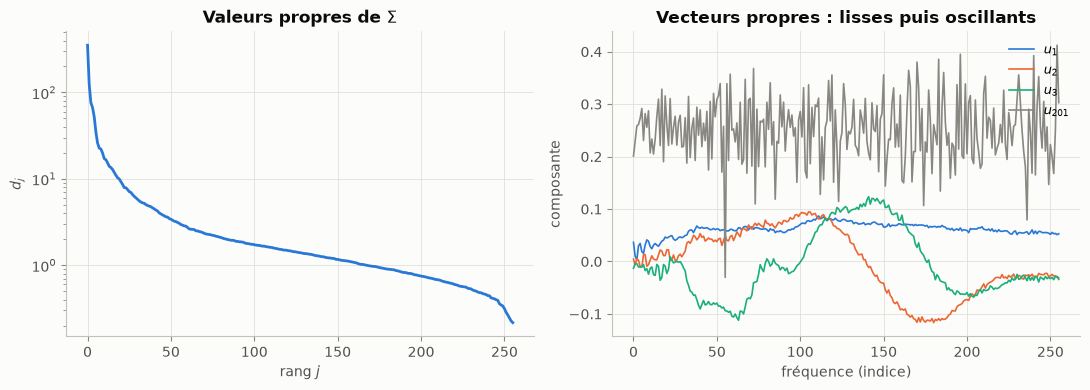

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogy(dS, color=BLUE)
axes[0].set_title("Valeurs propres de $\\Sigma$"); axes[0].set_xlabel("rang $j$"); axes[0].set_ylabel("$d_j$")
for j, c in zip([0, 1, 2, 200], [BLUE, ORANGE, GREEN, GRAY]):
    axes[1].plot(US[:, j] + (0.25 if j == 200 else 0), color=c, lw=1.2, label="$u_{%d}$" % (j + 1))
axes[1].set_title("Vecteurs propres : lisses puis oscillants")
axes[1].set_xlabel("fréquence (indice)"); axes[1].set_ylabel("composante"); axes[1].legend()
plt.tight_layout(); plt.show()

Comparons maintenant les métriques par un classifieur des **15 plus proches voisins**
(vote majoritaire), en écrivant $\mathbf A = \mathbf R^T\mathbf R$ : la distance associée est
la distance euclidienne entre les $\mathbf Rx$. On utilise la base de cosinus discrets
(ordonnée par fréquence) pour les choix (a) et (b).

In [14]:
p_ = Xp.shape[1]
tgrid = np.arange(p_)
Cb = np.column_stack([np.cos(np.pi * j * (tgrid + 0.5) / p_) for j in range(p_)])
Cb /= np.linalg.norm(Cb, axis=0)

def knn_error(Rm, k=15):
    Ztr, Zte = Xtr @ Rm.T, Xte @ Rm.T
    D = (Zte ** 2).sum(1)[:, None] + (Ztr ** 2).sum(1)[None, :] - 2 * Zte @ Ztr.T
    idx = np.argsort(D, axis=1)[:, :k]
    return np.mean((ytr[idx].mean(1) > 0.5) != yte)

gam = 1 / (1 + (np.arange(p_) / 15.0) ** 4)
metrics = {
    "A = I (euclidienne)": np.eye(p_),
    "A = Σ⁻¹ (Mahalanobis)": (US / np.sqrt(dS)).T,
    "A = Σ": (US * np.sqrt(dS)).T,
    "(a) passe-bas cosinus": (Cb * gam).T,
    "(b) projection, M = 10": Cb[:, :10].T,
    "(b) projection, M = 20": Cb[:, :20].T,
}
errs = {name: knn_error(Rm) for name, Rm in metrics.items()}
for name, e in errs.items():
    print("%-26s erreur test = %.3f" % (name, e))

A = I (euclidienne)        erreur test = 0.203
A = Σ⁻¹ (Mahalanobis)      erreur test = 0.308
A = Σ                      erreur test = 0.223
(a) passe-bas cosinus      erreur test = 0.212
(b) projection, M = 10     erreur test = 0.221
(b) projection, M = 20     erreur test = 0.203


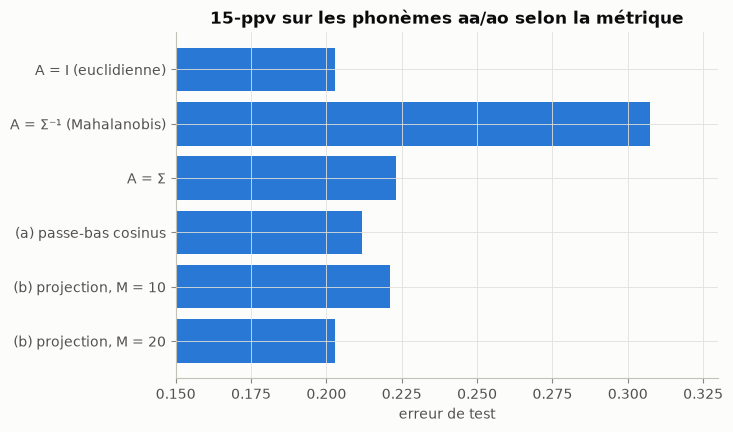

In [15]:
plt.figure(figsize=(7, 4.5))
names_m = list(errs)
plt.barh(names_m[::-1], [errs[n] for n in names_m[::-1]], color=BLUE)
plt.title("15-ppv sur les phonèmes aa/ao selon la métrique")
plt.xlabel("erreur de test"); plt.xlim(0.15, 0.33); plt.show()

La métrique de Mahalanobis est nettement la pire (elle amplifie les composantes de bruit) ;
les métriques qui atténuent ou suppriment les hautes fréquences font à peu près aussi bien
que la distance euclidienne (la projection sur 20 cosinus l'égale), avec beaucoup moins de
dimensions effectives. Ici les composantes de haute fréquence ne portent presque pas
d'information discriminante : les ignorer ne coûte rien, les surpondérer coûte cher.

> **À retenir.** Pour des prédicteurs issus de courbes, $\Sigma^{-1}$ surpondère les
> directions de faible variance, c'est-à-dire les hautes fréquences bruitées. Mieux vaut
> une métrique $\mathbf A = \sum_j\gamma_jv_jv_j^T$ à poids décroissants en fréquence (a), ou
> un projecteur sur une base lisse de petite dimension (b).

## Exercice 6.5 : Logit multinomial localement constant

**Énoncé.** Montrer qu'ajuster un modèle logit multinomial **localement constant** de la
forme (6.19) revient à lisser séparément les indicatrices binaires de chaque classe par un
lisseur de Nadaraya-Watson de poids $K_\lambda(x_0, x_i)$.

**Rappel.** Le modèle logit multinomial à $J$ classes (classe $J$ de référence,
$\beta_J = 0$) s'écrit $\Pr(G=j\mid x) = e^{\eta_j}/\sum_{k=1}^J e^{\eta_k}$. La version
localement constante prend des $\eta_j = \beta_{j0}(x_0)$ ne dépendant pas de $x$ dans la
fenêtre. La log-vraisemblance locale (6.19) vaut alors
$$
\ell(\beta) = \sum_{i=1}^N K_i\Big[\beta_{g_i0} - \log\Big(1 + \sum_{k=1}^{J-1}e^{\beta_{k0}}\Big)\Big],
\qquad K_i = K_\lambda(x_0, x_i).
$$

**Solution.** Notons $p_j = e^{\beta_{j0}}/(1 + \sum_k e^{\beta_{k0}})$. On dérive par
rapport à $\beta_{j0}$ ($j < J$), en utilisant
$\partial_{\beta_{j0}}\log(1 + \sum_k e^{\beta_{k0}}) = p_j$ :
$$
\frac{\partial\ell}{\partial\beta_{j0}} = \sum_i K_i\big[\mathbf 1(g_i = j) - p_j\big] = 0
\iff p_j = \frac{\sum_i K_i\,\mathbf 1(g_i = j)}{\sum_i K_i}.
$$
C'est exactement l'estimateur de Nadaraya-Watson appliqué à la réponse binaire
$\mathbf 1(g_i = j)$. Pour la classe $J$, $p_J = 1 - \sum_{j<J}p_j$ donne la même formule.

**Justification que c'est le maximum.** $\ell$ est concave (le « log-somme-exp » est
convexe), donc tout point critique est un maximum global. De plus, l'application
$\beta\mapsto(p_1,\dots,p_{J-1})$ est une bijection de $\mathbb R^{J-1}$ sur
$\{p_j > 0,\ \sum_{j<J}p_j < 1\}$ : si toutes les classes sont présentes dans la fenêtre, le
maximum existe et est unique, avec $\hat\beta_{j0} = \log(\hat p_j/\hat p_J)$. Si une classe
est absente de la fenêtre, le supremum n'est pas atteint ($\beta_{j0}\to-\infty$) mais les
probabilités tendent vers les mêmes valeurs (avec $\hat p_j = 0$).

Vérification numérique : 3 classes, maximisation directe de la vraisemblance locale par
`scipy.optimize.minimize`, comparée au lissage des indicatrices.

In [16]:
from scipy.optimize import minimize
n3 = 300
x3 = rng.uniform(0, 1, n3)
logits = np.column_stack([3 * x3, 1.5 * np.ones(n3), np.zeros(n3)])
pr = np.exp(logits) / np.exp(logits).sum(1, keepdims=True)
g3 = np.array([rng.choice(3, p=pi) for pi in pr])

def neg_local_loglik(b, w):
    eta = np.r_[b, 0.0]
    return -np.sum(w * (eta[g3] - np.log(np.sum(np.exp(eta)))))

for x0 in [0.2, 0.5, 0.8]:
    w = nk.kernel_weights([x0], x3, lam=0.2, kernel="tricube")[0]
    bopt = minimize(neg_local_loglik, np.zeros(2), args=(w,), method="BFGS", options={"gtol": 1e-10}).x
    eta = np.r_[bopt, 0.0]
    p_ml = np.exp(eta) / np.exp(eta).sum()
    p_nw = [nk.nadaraya_watson([x0], x3, (g3 == j).astype(float), lam=0.2, kernel="tricube")[0]
            for j in range(3)]
    print("x0 = %.1f  max. vraisemblance : %s   Nadaraya-Watson : %s"
          % (x0, np.round(p_ml, 5), np.round(p_nw, 5)))

x0 = 0.2  max. vraisemblance : [0.22255 0.59979 0.17766]   Nadaraya-Watson : [0.22255 0.59979 0.17766]
x0 = 0.5  max. vraisemblance : [0.54091 0.37173 0.08737]   Nadaraya-Watson : [0.54091 0.37173 0.08737]
x0 = 0.8  max. vraisemblance : [0.61178 0.25977 0.12845]   Nadaraya-Watson : [0.61178 0.25977 0.12845]
